# Image Quality Assessment Using Deep Learning

This notebook trains a no-reference image quality model on KonIQ-10k. It takes an image and
predicts the quality score that people gave to images like it, on the 0 to 100 MOS scale
published in the KonIQ-10k score file.

Run the sections in order. Section 11 (test evaluation) should be run only once, at the very
end, when nothing more will be changed.

Before starting: Runtime, Change runtime type, and pick a GPU.

## 1. Setup

This section imports the libraries, fixes the random seed so the same run can be repeated,
mounts Google Drive and creates the folders used by the rest of the notebook.

The dataset is kept in /content, which is the fast local disk of the Colab machine. Anything
that must survive a disconnect (the dataset zip, the trained model, the results) is copied to
Drive.

Note the TensorFlow version that is printed. The Streamlit app on your laptop has to use the
same version, otherwise the saved model may not load there.

In [1]:
import os, json, random, shutil, time, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE = pathlib.Path("/content/drive/MyDrive/iqa_project")
DRIVE.mkdir(parents=True, exist_ok=True)

ROOT    = pathlib.Path("/content/iqa")
RAW     = ROOT / "data" / "raw"
SPLITS  = ROOT / "data" / "splits"
MODELS  = ROOT / "models"
FIGS    = ROOT / "outputs" / "figures"
LOGS    = ROOT / "outputs" / "logs"
RESULTS = ROOT / "outputs" / "results"

for p in [RAW, SPLITS, MODELS, FIGS, LOGS, RESULTS]:
    p.mkdir(parents=True, exist_ok=True)

print("working folder:", ROOT)
print("drive folder  :", DRIVE)

Mounted at /content/drive
working folder: /content/iqa
drive folder  : /content/drive/MyDrive/iqa_project


## 2. Download KonIQ-10k

Two things are needed: the images and the file with the human scores.

The images are downloaded as a zip of about 0.75 GB in the 512x384 version. The zip is saved to
Drive, so if the session disconnects the next run copies it from Drive instead of downloading
it again. It is unzipped into /content because reading ten thousand small files from Drive is
very slow.

The score file is a small CSV that lists every image name with its MOS (mean opinion score).

In [3]:
IMAGES_URL = "http://datasets.vqa.mmsp-kn.de/archives/koniq10k_512x384.zip"
SCORES_URL = "https://raw.githubusercontent.com/subpic/koniq/master/metadata/koniq10k_distributions_sets.csv"

zip_path = DRIVE / "koniq10k_512x384.zip"
if not zip_path.exists():
    print("downloading images, this takes a few minutes")
    !wget -q --show-progress -O "{zip_path}" "{IMAGES_URL}"
print("zip size (GB):", round(zip_path.stat().st_size / 1e9, 2))

downloading images, this takes a few minutes
/content/drive/MyDr 100%[===================>] 731.44M  18.9MB/s    in 40s     
zip size (GB): 0.77


In [4]:
if not any(RAW.rglob("*.jpg")):
    print("unzipping")
    !unzip -q "{zip_path}" -d "{RAW}"

IMAGE_DIR = next(RAW.rglob("*.jpg")).parent
print("images folder:", IMAGE_DIR)
print("image files  :", len(list(IMAGE_DIR.glob("*.jpg"))))

unzipping
images folder: /content/iqa/data/raw/512x384
image files  : 10373


In [5]:
scores_csv = RAW / "koniq10k_scores.csv"
if not scores_csv.exists():
    !wget -q -O "{scores_csv}" "{SCORES_URL}"

scores_raw = pd.read_csv(scores_csv)
print("columns:", list(scores_raw.columns))
scores_raw.head()

columns: ['image_name', 'c1', 'c2', 'c3', 'c4', 'c5', 'c_total', 'MOS', 'SD', 'set']


,image_name,c1,c2,c3,c4,c5,c_total,MOS,SD,set
0,10004473376.jpg,0.000000,0.00000,0.238095,0.695238,0.066667,105,77.383621,0.527278,training
1,10007357496.jpg,0.000000,0.03125,0.468750,0.489583,0.010417,96,68.728571,0.580003,test
2,10007903636.jpg,0.010417,0.00000,0.208333,0.760417,0.020833,96,78.628571,0.527220,training
3,10009096245.jpg,0.000000,0.00000,0.192661,0.688073,0.119266,109,77.243750,0.556218,training
4,100117038.jpg,0.000000,0.01000,0.210000,0.720000,0.060000,100,75.112500,0.532860,training


## 3. Check the data and look at the scores

The score file has several columns. Only two are needed: the image name and the MOS. The code
below finds those two columns, drops rows whose image file is missing, and prints the basic
statistics of the scores.

It also works out the range of the score column. The distributions file used here publishes
the MOS on a 0 to 100 scale, while other copies use the original 1 to 5 scale, so the range is
read from the data instead of being assumed.

The histogram shows something important for later: most images sit in the middle of the scale
and very few are extremely bad or extremely good. A model trained on this will be accurate in
the middle and will pull extreme images towards the centre.

In [6]:
image_col = [c for c in scores_raw.columns if "image" in c.lower()][0]
mos_col   = [c for c in scores_raw.columns if c.lower() == "mos"][0]
print("using columns:", image_col, "and", mos_col)

data = scores_raw[[image_col, mos_col]].rename(columns={image_col: "image_name", mos_col: "mos"})
data = data.dropna()
data["path"] = data["image_name"].map(lambda n: str(IMAGE_DIR / n))

found = data["path"].map(os.path.exists)
print("rows in score file :", len(data))
print("images not on disk :", int((~found).sum()))
data = data[found].reset_index(drop=True)

MOS_MIN, MOS_MAX = (0.0, 100.0) if data["mos"].max() > 5.5 else (1.0, 5.0)
print("score scale:", MOS_MIN, "to", MOS_MAX)
data["mos"].describe()

using columns: image_name and MOS
rows in score file : 10073
images not on disk : 0
score scale: 0.0 to 100.0


,mos
count,10073.000000
mean,58.729617
std,15.432433
min,3.911765
25%,49.247768
50%,62.354369
75%,70.712500
max,88.388889


In [7]:
stats = {
    "images_used": int(len(data)),
    "scale_min": MOS_MIN,
    "scale_max": MOS_MAX,
    "mos_min": float(data["mos"].min()),
    "mos_max": float(data["mos"].max()),
    "mos_mean": float(data["mos"].mean()),
    "mos_std": float(data["mos"].std()),
    "mos_median": float(data["mos"].median()),
}
(RESULTS / "dataset_stats.json").write_text(json.dumps(stats, indent=2))
stats

{'images_used': 10073,
 'scale_min': 0.0,
 'scale_max': 100.0,
 'mos_min': 3.91176470588,
 'mos_max': 88.3888888889,
 'mos_mean': 58.72961657682714,
 'mos_std': 15.43243283435167,
 'mos_median': 62.354368932}

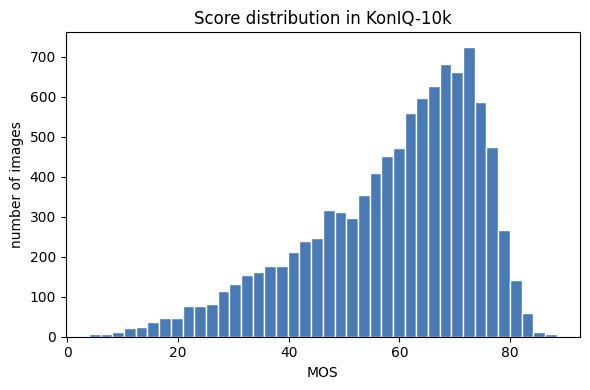

In [8]:
plt.figure(figsize=(6, 4))
plt.hist(data["mos"], bins=40, color="#4a7ab5", edgecolor="white")
plt.xlabel("MOS")
plt.ylabel("number of images")
plt.title("Score distribution in KonIQ-10k")
plt.tight_layout()
plt.savefig(FIGS / "mos_histogram.png", dpi=200)
plt.show()

Below are three images from the low, middle and high end of the scale. They are a quick check
that the scores make sense before any training starts.

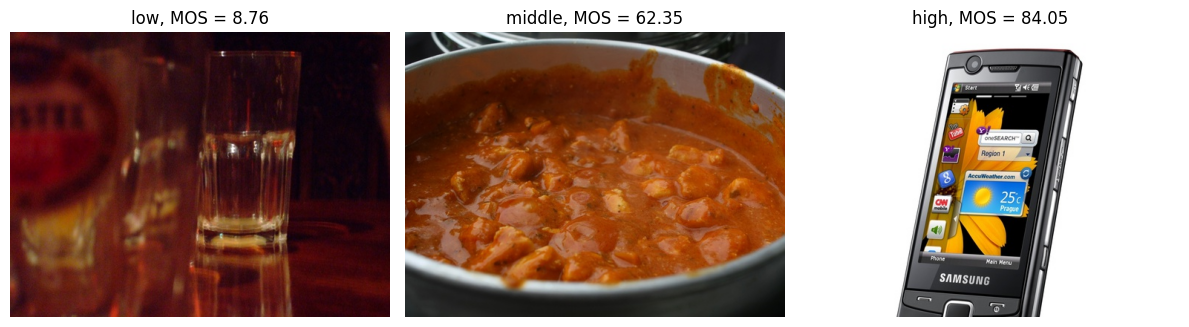

In [9]:
from PIL import Image

sorted_data = data.sort_values("mos").reset_index(drop=True)
picks = {
    "low": sorted_data.iloc[20],
    "middle": sorted_data.iloc[len(sorted_data) // 2],
    "high": sorted_data.iloc[-20],
}

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, row) in zip(axes, picks.items()):
    ax.imshow(Image.open(row["path"]))
    ax.set_title(f"{name}, MOS = {row['mos']:.2f}")
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIGS / "sample_images.png", dpi=200)
plt.show()

## 4. Split into training, validation and test sets

The images are shuffled once with a fixed seed and cut into 80 percent for training,
10 percent for validation and 10 percent for testing. The seed keeps the split identical
in every later run.

The validation set is used while training, to pick the best epoch. The test set is not
touched until section 11.

The three lists are written to CSV files so the app and any later script use exactly the same
division.

In [10]:
shuffled = data.sample(frac=1, random_state=SEED).reset_index(drop=True)
n = len(shuffled)
n_train, n_val = int(0.8 * n), int(0.1 * n)

train_df = shuffled.iloc[:n_train].reset_index(drop=True)
val_df   = shuffled.iloc[n_train:n_train + n_val].reset_index(drop=True)
test_df  = shuffled.iloc[n_train + n_val:].reset_index(drop=True)

for name, frame in [("train", train_df), ("val", val_df), ("test", test_df)]:
    frame[["image_name", "mos"]].to_csv(SPLITS / f"{name}.csv", index=False)

split_stats = {
    name: {"images": len(f), "mos_mean": float(f["mos"].mean()), "mos_std": float(f["mos"].std())}
    for name, f in [("train", train_df), ("val", val_df), ("test", test_df)]
}
(RESULTS / "split_stats.json").write_text(json.dumps(split_stats, indent=2))
split_stats

{'train': {'images': 8058,
  'mos_mean': 58.80224507674435,
  'mos_std': 15.408245438453557},
 'val': {'images': 1007,
  'mos_mean': 58.336561453661055,
  'mos_std': 15.646164655976063},
 'test': {'images': 1008,
  'mos_mean': 58.54168607751706,
  'mos_std': 15.418606763745606}}

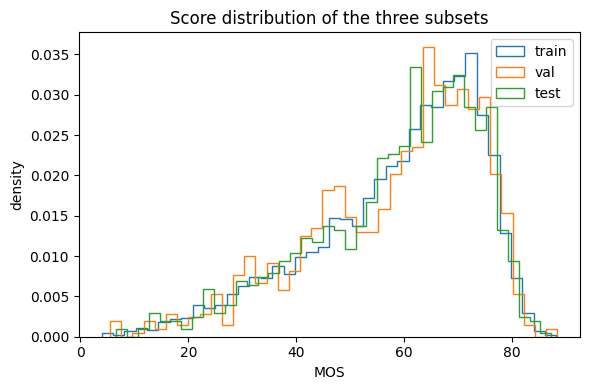

In [11]:
plt.figure(figsize=(6, 4))
for name, frame in [("train", train_df), ("val", val_df), ("test", test_df)]:
    plt.hist(frame["mos"], bins=40, density=True, histtype="step", label=name)
plt.xlabel("MOS")
plt.ylabel("density")
plt.title("Score distribution of the three subsets")
plt.legend()
plt.tight_layout()
plt.savefig(FIGS / "split_histograms.png", dpi=200)
plt.show()

## 5. Input pipeline

Every image goes through the same few steps: read the file, decode it, resize it to 224 by 224
and apply the scaling that MobileNetV2 expects, which maps pixel values into the range -1 to 1.

The scores are rescaled to the range 0 to 1 for training and converted back to the original
scale whenever a result is reported.

Training images are flipped left to right at random. This is the only augmentation used.
Anything stronger, such as extra blur or a brightness change, would alter the quality of the
image, and the score attached to it would no longer be correct.

In [12]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

def normalize_mos(values):
    return (np.asarray(values, dtype="float32") - MOS_MIN) / (MOS_MAX - MOS_MIN)

def denormalize_mos(values):
    return np.asarray(values, dtype="float32") * (MOS_MAX - MOS_MIN) + MOS_MIN

def read_image(path, training):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    if training:
        image = tf.image.random_flip_left_right(image)
    return preprocess_input(image)

def build_dataset(frame, training=False, cache=False):
    paths = frame["path"].values
    labels = normalize_mos(frame["mos"].values)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda p, y: (read_image(p, training), y), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    if cache:
        ds = ds.cache()
    return ds.prefetch(AUTOTUNE)

train_ds = build_dataset(train_df, training=True)
val_ds   = build_dataset(val_df, cache=True)
print("batches per epoch:", len(train_ds))

batches per epoch: 252


A quick look at one batch after preprocessing. The images are shown with the scaling undone,
so they should look normal. If they look wrong here, they will be wrong during training too.

image batch: (32, 224, 224, 3) <dtype: 'float32'>
label batch: (32,) range 0.23290865123271942 to 0.8053640723228455


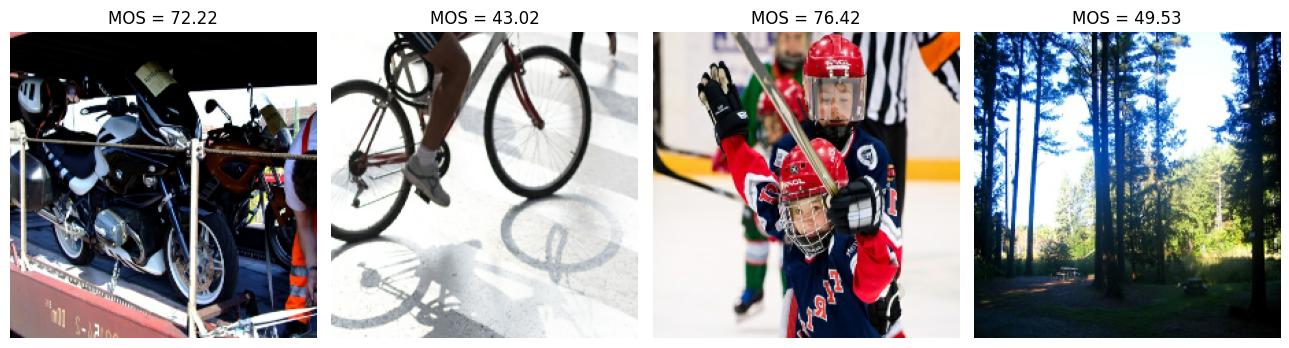

In [13]:
images, labels = next(iter(train_ds))
print("image batch:", images.shape, images.dtype)
print("label batch:", labels.shape, "range", float(tf.reduce_min(labels)), "to", float(tf.reduce_max(labels)))

fig, axes = plt.subplots(1, 4, figsize=(13, 3.5))
for ax, img, lab in zip(axes, images[:4], labels[:4]):
    ax.imshow((img.numpy() + 1) / 2)
    ax.set_title(f"MOS = {denormalize_mos(lab.numpy()):.2f}")
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIGS / "preprocessed_batch.png", dpi=200)
plt.show()

## 6. Build the model

MobileNetV2 is loaded with the weights it learned on ImageNet and without its classification
layer, so it acts as a feature extractor. Its output is pooled into a vector of 1280 numbers,
which passes through a small dense layer, dropout, and a final single neuron that produces the
quality score.

The backbone is frozen to begin with, so only the new layers are trained. It is also called
with training=False, which keeps its batch normalisation layers in inference mode. This matters
later, when part of the backbone is unfrozen.

The loss is mean squared error because this is a regression problem, and mean absolute error is
tracked because it is easier to read.

In [14]:
def build_model():
    base = tf.keras.applications.MobileNetV2(
        input_shape=IMAGE_SIZE + (3,), include_top=False, weights="imagenet"
    )
    base.trainable = False

    inputs = tf.keras.Input(shape=IMAGE_SIZE + (3,))
    x = base(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(128, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(1, activation="linear")(x)
    return tf.keras.Model(inputs, outputs), base

model, base_model = build_model()
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])

print("layers in the backbone:", len(base_model.layers))
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
layers in the backbone: 154


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [15]:
with open(RESULTS / "model_summary.txt", "w") as f:
    model.summary(print_fn=lambda line: f.write(line + "\n"))
print("saved model summary")

saved model summary


## 7. Train the regression head

In this first phase the backbone stays frozen and only the new layers learn. Training stops
early if the validation loss stops improving, and the weights from the best epoch are kept.

In [16]:
EPOCHS_PHASE1 = 12

callbacks_1 = [
    tf.keras.callbacks.ModelCheckpoint(str(MODELS / "phase1_best.keras"),
                                       monitor="val_loss", save_best_only=True),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                     restore_best_weights=True),
    tf.keras.callbacks.CSVLogger(str(LOGS / "phase1_log.csv")),
]

start = time.time()
history1 = model.fit(train_ds, validation_data=val_ds,
                     epochs=EPOCHS_PHASE1, callbacks=callbacks_1)
phase1_minutes = (time.time() - start) / 60
print("phase 1 took", round(phase1_minutes, 1), "minutes")

Epoch 1/12
252/252 ━━━━━━━━━━━━━━━━━━━━ 68s 187ms/step - loss: 0.0818 - mae: 0.2011 - val_loss: 0.0205 - val_mae: 0.1132
Epoch 2/12
252/252 ━━━━━━━━━━━━━━━━━━━━ 17s 68ms/step - loss: 0.0257 - mae: 0.1279 - val_loss: 0.0188 - val_mae: 0.1123
Epoch 3/12
252/252 ━━━━━━━━━━━━━━━━━━━━ 21s 71ms/step - loss: 0.0196 - mae: 0.1122 - val_loss: 0.0150 - val_mae: 0.0988
Epoch 4/12
252/252 ━━━━━━━━━━━━━━━━━━━━ 17s 68ms/step - loss: 0.0155 - mae: 0.0997 - val_loss: 0.0126 - val_mae: 0.0899
Epoch 5/12
252/252 ━━━━━━━━━━━━━━━━━━━━ 22s 74ms/step - loss: 0.0133 - mae: 0.0921 - val_loss: 0.0120 - val_mae: 0.0867
Epoch 6/12
252/252 ━━━━━━━━━━━━━━━━━━━━ 17s 69ms/step - loss: 0.0122 - mae: 0.0884 - val_loss: 0.0118 - val_mae: 0.0850
Epoch 7/12
252/252 ━━━━━━━━━━━━━━━━━━━━ 26s 89ms/step - loss: 0.0114 - mae: 0.0852 - val_loss: 0.0118 - val_mae: 0.0869
Epoch 8/12
252/252 ━━━━━━━━━━━━━━━━━━━━ 17s 69ms/step - loss: 0.0104 - mae: 0.0808 - val_loss: 0.0109 - val_mae: 0.0813
Epoch 9/12
252/252 ━━━━━━━━━━━━━━━━━━━━

## 8. Fine-tune the top of the backbone

Now the upper part of MobileNetV2 is unfrozen so that the features themselves can adapt to
quality cues such as blur and noise. The lower layers stay frozen because they detect very
general patterns that do not need changing.

The learning rate drops to 1e-5. A larger one here would destroy the pretrained weights.
After changing which layers are trainable the model has to be compiled again.

In [17]:
FINE_TUNE_AT = 100
EPOCHS_PHASE2 = 10

base_model.trainable = True
for layer in base_model.layers[:FINE_TUNE_AT]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss="mse", metrics=["mae"])
print("trainable weights:", len(model.trainable_weights))

callbacks_2 = [
    tf.keras.callbacks.ModelCheckpoint(str(MODELS / "iqa_mobilenetv2.keras"),
                                       monitor="val_loss", save_best_only=True),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                     restore_best_weights=True),
    tf.keras.callbacks.CSVLogger(str(LOGS / "phase2_log.csv")),
]

start = time.time()
history2 = model.fit(train_ds, validation_data=val_ds,
                     epochs=EPOCHS_PHASE2, callbacks=callbacks_2)
phase2_minutes = (time.time() - start) / 60
print("phase 2 took", round(phase2_minutes, 1), "minutes")

model.save(MODELS / "iqa_mobilenetv2.keras")

trainable weights: 58
Epoch 1/10
252/252 ━━━━━━━━━━━━━━━━━━━━ 62s 152ms/step - loss: 0.0105 - mae: 0.0807 - val_loss: 0.0122 - val_mae: 0.0834
Epoch 2/10
252/252 ━━━━━━━━━━━━━━━━━━━━ 18s 70ms/step - loss: 0.0093 - mae: 0.0760 - val_loss: 0.0113 - val_mae: 0.0803
Epoch 3/10
252/252 ━━━━━━━━━━━━━━━━━━━━ 18s 70ms/step - loss: 0.0086 - mae: 0.0730 - val_loss: 0.0109 - val_mae: 0.0788
Epoch 4/10
252/252 ━━━━━━━━━━━━━━━━━━━━ 20s 79ms/step - loss: 0.0080 - mae: 0.0706 - val_loss: 0.0105 - val_mae: 0.0775
Epoch 5/10
252/252 ━━━━━━━━━━━━━━━━━━━━ 18s 71ms/step - loss: 0.0075 - mae: 0.0682 - val_loss: 0.0102 - val_mae: 0.0766
Epoch 6/10
252/252 ━━━━━━━━━━━━━━━━━━━━ 18s 69ms/step - loss: 0.0072 - mae: 0.0667 - val_loss: 0.0097 - val_mae: 0.0751
Epoch 7/10
252/252 ━━━━━━━━━━━━━━━━━━━━ 20s 68ms/step - loss: 0.0068 - mae: 0.0647 - val_loss: 0.0099 - val_mae: 0.0757
Epoch 8/10
252/252 ━━━━━━━━━━━━━━━━━━━━ 20s 67ms/step - loss: 0.0065 - mae: 0.0633 - val_loss: 0.0104 - val_mae: 0.0775
Epoch 9/10
252/25

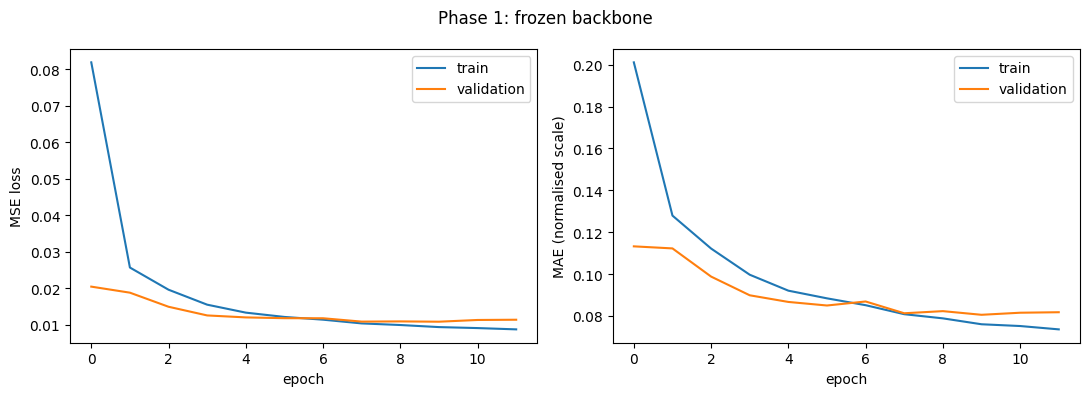

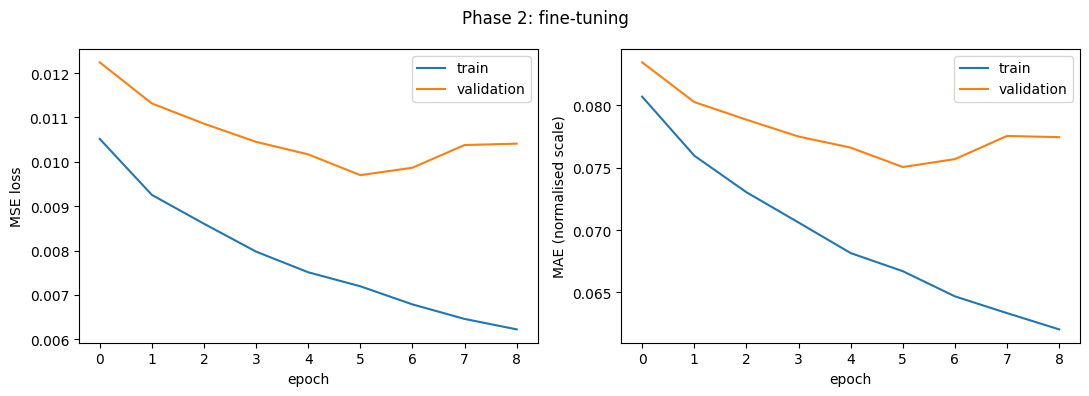

In [18]:
def plot_history(history, title, filename):
    hist = history.history
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(hist["loss"], label="train")
    axes[0].plot(hist["val_loss"], label="validation")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("MSE loss"); axes[0].legend()
    axes[1].plot(hist["mae"], label="train")
    axes[1].plot(hist["val_mae"], label="validation")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("MAE (normalised scale)"); axes[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(FIGS / filename, dpi=200)
    plt.show()

plot_history(history1, "Phase 1: frozen backbone", "phase1_curves.png")
plot_history(history2, "Phase 2: fine-tuning", "phase2_curves.png")

## 9. Evaluate on the validation set

Four numbers are reported. MAE and MSE say how far the predictions are from the human scores,
in the units of the original scale. SROCC says whether the model ranks images in the same order
as people do, and PLCC says how linear the relationship is. Both correlations are between -1
and 1, and higher is better.

The scatter plot shows every validation image as one point. A good model produces a cloud that
follows the diagonal line.

In [19]:
from scipy.stats import spearmanr, pearsonr

def evaluate_split(model, frame, name):
    ds = build_dataset(frame, training=False)
    predicted = denormalize_mos(model.predict(ds, verbose=1).squeeze())
    actual = frame["mos"].values.astype("float32")

    results = {
        "images": int(len(frame)),
        "mae": float(np.mean(np.abs(predicted - actual))),
        "mse": float(np.mean((predicted - actual) ** 2)),
        "srocc": float(spearmanr(predicted, actual)[0]),
        "plcc": float(pearsonr(predicted, actual)[0]),
    }
    (RESULTS / f"{name}_metrics.json").write_text(json.dumps(results, indent=2))
    print(name, results)
    return predicted, actual, results

val_pred, val_true, val_results = evaluate_split(model, val_df, "val")

32/32 ━━━━━━━━━━━━━━━━━━━━ 11s 189ms/step
val {'images': 1007, 'mae': 7.505362033843994, 'mse': 96.9935302734375, 'srocc': 0.7603243390963016, 'plcc': 0.7970949411392212}


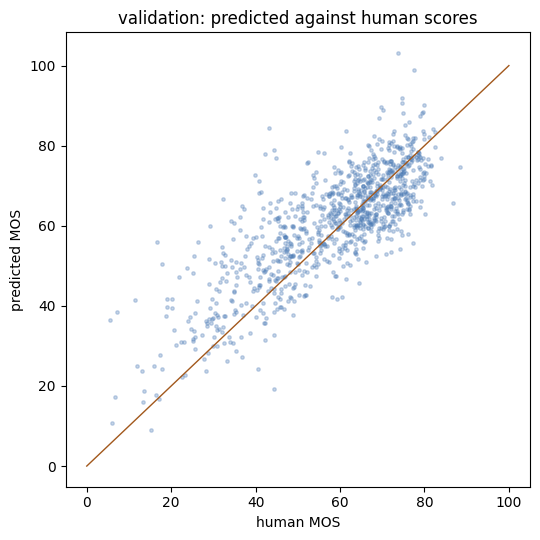

In [20]:
def plot_scatter(predicted, actual, name):
    plt.figure(figsize=(5.5, 5.5))
    plt.scatter(actual, predicted, s=6, alpha=0.3, color="#4a7ab5")
    limits = [MOS_MIN, MOS_MAX]
    plt.plot(limits, limits, color="#a2581c", linewidth=1)
    plt.xlabel("human MOS")
    plt.ylabel("predicted MOS")
    plt.title(f"{name}: predicted against human scores")
    plt.tight_layout()
    plt.savefig(FIGS / f"{name}_scatter.png", dpi=200)
    plt.show()

plot_scatter(val_pred, val_true, "validation")

The next cell splits the validation images into a low, middle and high group and reports the
error in each. This usually shows the pattern mentioned in section 3: the middle of the scale
is predicted best.

In [21]:
low_cut, high_cut = np.percentile(train_df["mos"], [33, 67])
groups = {
    "low": val_true <= low_cut,
    "middle": (val_true > low_cut) & (val_true < high_cut),
    "high": val_true >= high_cut,
}
by_range = {name: {"images": int(mask.sum()),
                   "mae": float(np.mean(np.abs(val_pred[mask] - val_true[mask])))}
            for name, mask in groups.items()}
(RESULTS / "val_mae_by_range.json").write_text(json.dumps(by_range, indent=2))
by_range

{'low': {'images': 352, 'mae': 10.325350761413574},
 'middle': {'images': 341, 'mae': 5.685582160949707},
 'high': {'images': 314, 'mae': 6.320358753204346}}

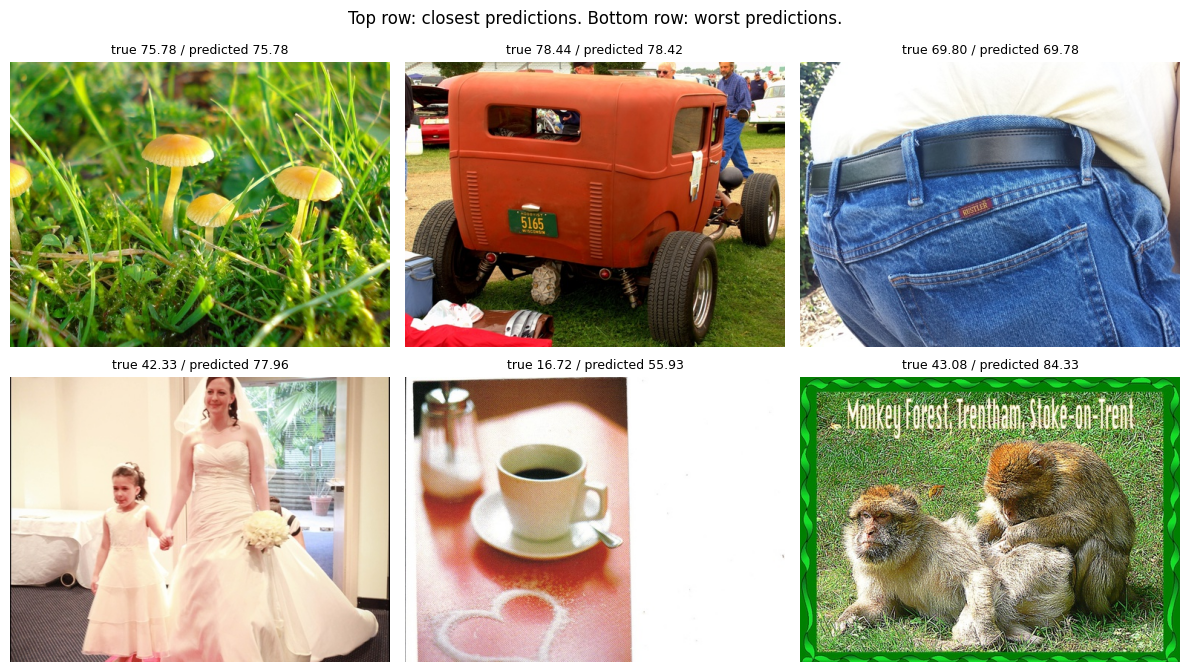

In [22]:
order = np.argsort(np.abs(val_pred - val_true))
best, worst = order[:3], order[-3:]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, i in zip(axes[0], best):
    ax.imshow(Image.open(val_df.iloc[i]["path"]))
    ax.set_title(f"true {val_true[i]:.2f} / predicted {val_pred[i]:.2f}", fontsize=9)
    ax.axis("off")
for ax, i in zip(axes[1], worst):
    ax.imshow(Image.open(val_df.iloc[i]["path"]))
    ax.set_title(f"true {val_true[i]:.2f} / predicted {val_pred[i]:.2f}", fontsize=9)
    ax.axis("off")
fig.suptitle("Top row: closest predictions. Bottom row: worst predictions.")
plt.tight_layout()
plt.savefig(FIGS / "validation_examples.png", dpi=200)
plt.show()

## 10. Quality levels and the extra image measurements

The model outputs a number. The app also shows a word, so the score is split into Poor, Average
and Good using the lower and upper third of the training scores. Taking the cut points from the
data keeps them honest instead of being picked by hand.

The app also displays three simple measurements taken straight from the image with OpenCV:
sharpness, brightness and contrast. They are only there to help a person read the result. The
model does not use them. Their Low, Normal and High bands come from the same thirds, measured
over a sample of training images.

In [23]:
import cv2

def image_diagnostics(path):
    image = cv2.imread(str(path))
    image = cv2.resize(image, (512, 384))
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return {
        "sharpness": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
        "brightness": float(gray.mean()),
        "contrast": float(gray.std()),
    }

label_thresholds = {"scale_min": MOS_MIN, "scale_max": MOS_MAX,
                    "poor_below": float(low_cut), "good_above": float(high_cut)}
(MODELS / "label_thresholds.json").write_text(json.dumps(label_thresholds, indent=2))
label_thresholds

{'scale_min': 0.0,
 'scale_max': 100.0,
 'poor_below': 54.664146194944,
 'good_above': 68.350245689646}

In [24]:
sample = train_df.sample(1000, random_state=SEED)
measurements = pd.DataFrame([image_diagnostics(p) for p in sample["path"]])

diagnostic_thresholds = {
    column: {"low_below": float(np.percentile(measurements[column], 33)),
             "high_above": float(np.percentile(measurements[column], 67))}
    for column in measurements.columns
}
(MODELS / "diagnostic_thresholds.json").write_text(json.dumps(diagnostic_thresholds, indent=2))
diagnostic_thresholds

{'sharpness': {'low_below': 234.7473351737102,
  'high_above': 1144.223811911002},
 'brightness': {'low_below': 81.3575201924642, 'high_above': 131.164324798584},
 'contrast': {'low_below': 40.51149188668996, 'high_above': 64.91148665433523}}

This last cell puts the pieces together the way the app will: one image in, a score, a level and
the three measurements out. Try it on a few images before moving on.

In [25]:
def band(value, thresholds):
    if value < thresholds["low_below"]:
        return "Low"
    if value > thresholds["high_above"]:
        return "High"
    return "Normal"

def assess(path):
    image = tf.image.resize(tf.image.decode_jpeg(tf.io.read_file(str(path)), channels=3), IMAGE_SIZE)
    prediction = model.predict(preprocess_input(image)[None, ...], verbose=0)[0, 0]
    mos = float(denormalize_mos(prediction))
    level = "Poor" if mos < low_cut else ("Good" if mos > high_cut else "Average")
    measures = image_diagnostics(path)
    return {
        "mos": round(mos, 2),
        "score_100": round(100 * (mos - MOS_MIN) / (MOS_MAX - MOS_MIN)),
        "level": level,
        "diagnostics": {k: (round(v, 1), band(v, diagnostic_thresholds[k])) for k, v in measures.items()},
    }

for i in [0, 1, 2]:
    print(val_df.iloc[i]["image_name"], "true MOS", round(val_df.iloc[i]["mos"], 2))
    print("   ", assess(val_df.iloc[i]["path"]))

5517232825.jpg true MOS 67.07
    {'mos': 67.83, 'score_100': 68, 'level': 'Average', 'diagnostics': {'sharpness': (3012.8, 'High'), 'brightness': (81.4, 'Normal'), 'contrast': (67.5, 'High')}}
8625160006.jpg true MOS 43.11
    {'mos': 54.83, 'score_100': 55, 'level': 'Average', 'diagnostics': {'sharpness': (117.8, 'Low'), 'brightness': (69.4, 'Low'), 'contrast': (67.0, 'High')}}
6228278450.jpg true MOS 62.62
    {'mos': 67.73, 'score_100': 68, 'level': 'Average', 'diagnostics': {'sharpness': (649.1, 'Normal'), 'brightness': (158.6, 'High'), 'contrast': (91.6, 'High')}}


## 11. Test set

Run this section once, at the end, when the model will not be changed again. These are the
numbers that go into the final report.

Set RUN_TEST to True and run the cell.

In [ ]:
RUN_TEST = True

if RUN_TEST:
    test_pred, test_true, test_results = evaluate_split(model, test_df, "test")
    plot_scatter(test_pred, test_true, "test")
else:
    print("skipped, set RUN_TEST = True when the model is final")

## 12. Save everything

This copies the trained model, the threshold files, the split lists, the logs, the figures and
the result files into Drive, and also makes one zip that downloads to your computer. Unzip it
into the project folder so the app and the reports use the same files.

In [27]:
training_info = {
    "tensorflow": tf.__version__,
    "gpu": [d.name for d in tf.config.list_physical_devices("GPU")],
    "image_size": list(IMAGE_SIZE),
    "batch_size": BATCH_SIZE,
    "seed": SEED,
    "epochs_run_phase1": len(history1.history["loss"]),
    "epochs_run_phase2": len(history2.history["loss"]),
    "fine_tune_at": FINE_TUNE_AT,
    "minutes_phase1": round(phase1_minutes, 1),
    "minutes_phase2": round(phase2_minutes, 1),
}
(RESULTS / "training_info.json").write_text(json.dumps(training_info, indent=2))
training_info

{'tensorflow': '2.20.0',
 'gpu': ['/physical_device:GPU:0'],
 'image_size': [224, 224],
 'batch_size': 32,
 'seed': 42,
 'epochs_run_phase1': 12,
 'epochs_run_phase2': 9,
 'fine_tune_at': 100,
 'minutes_phase1': 4.7,
 'minutes_phase2': 3.5}

In [28]:
for folder in ["models", "outputs", "data/splits"]:
    source = ROOT / folder
    target = DRIVE / folder
    if target.exists():
        shutil.rmtree(target)
    shutil.copytree(source, target)
print("copied to Drive")

!cd "{ROOT}" && zip -qr /content/iqa_artifacts.zip models outputs data/splits
print("zip ready:", round(os.path.getsize("/content/iqa_artifacts.zip") / 1e6, 1), "MB")

from google.colab import files
files.download("/content/iqa_artifacts.zip")

copied to Drive
zip ready: 42.2 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>